In [2]:
import kagglehub

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

100%|██████████| 117M/117M [00:14<00:00, 8.35MB/s] 

Extracting model files...


Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [9]:
df = pd.read_csv(r'..\lab-eda-univariate\amz_uk_price_prediction_dataset.csv')

In [10]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [11]:
df.shape

(2443651, 9)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [13]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [14]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.

In [15]:
frequency_table = df['category'].value_counts()

- Which are the top 5 most listed product categories?

In [20]:
ft = frequency_table.head()

In [22]:
ft

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

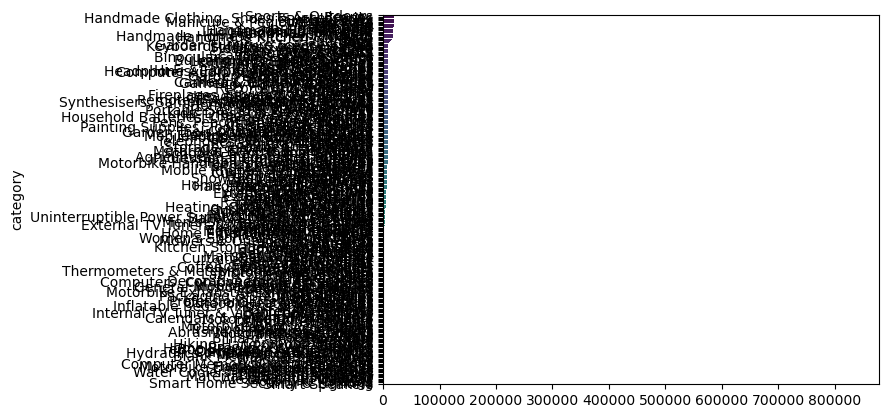

In [29]:
ax=sns.barplot(y=frequency_table.index, x=frequency_table.values, palette="viridis", hue=frequency_table.index, legend=False )
plt.show()

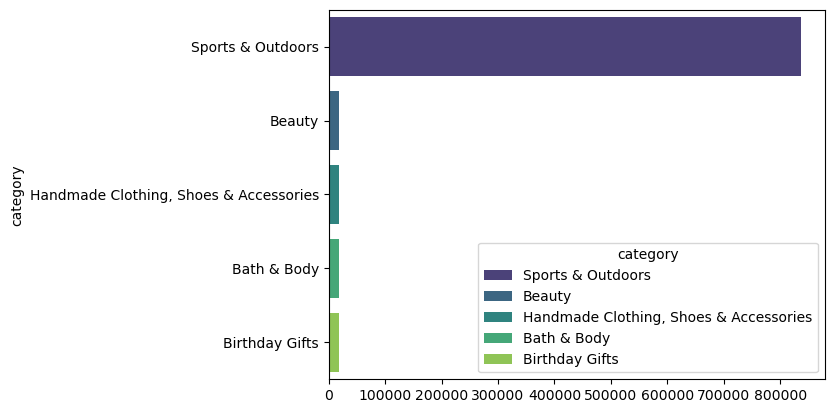

In [27]:
ax=sns.barplot(y=ft.index, x=ft.values, palette="viridis", hue=ft.index, legend=True )
sns.move_legend(ax, "lower right")
plt.show()

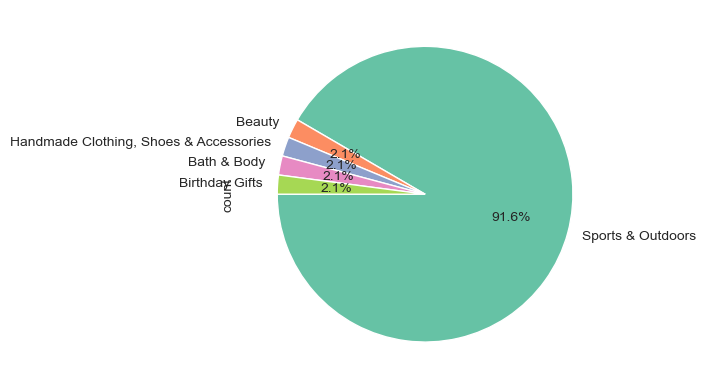

In [49]:
ft.plot.pie(autopct='%1.1f%%', startangle=180, colors=sns.color_palette("Set2"));
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?


In [50]:
df['price'].nunique()

82916

In [51]:
df['price'].value_counts()

price
9.99       48922
12.99      38823
8.99       34058
7.99       33632
14.99      32570
           ...  
2398.99        1
1453.08        1
1785.63        1
1347.36        1
317.34         1
Name: count, Length: 82916, dtype: int64

In [ ]:
## Yes. We can find more then 80000 unque values for price. 

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [53]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(mean_price)
print(median_price)
print(mode_price)

89.24380943923663
19.09
9.99


In [ ]:
## We can note that the most commom price is 9.99. With a high mean we can imply that have products with very high prices.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [57]:
variance_price = df['price'].var()
std_dev_price = df['price'].std()
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])

print(variance_price)
print(std_dev_price)
print(min_price)
print(max_price)
print(range_price)
print(quantiles_price)

119445.48532256528
345.60886175352226
0.0
100000.0
100000.0
0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64


In [ ]:
## The products show us a high variance in the prices. starting form 0.00 until 100000.0. In the range we can note a significant spread in prices. 

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

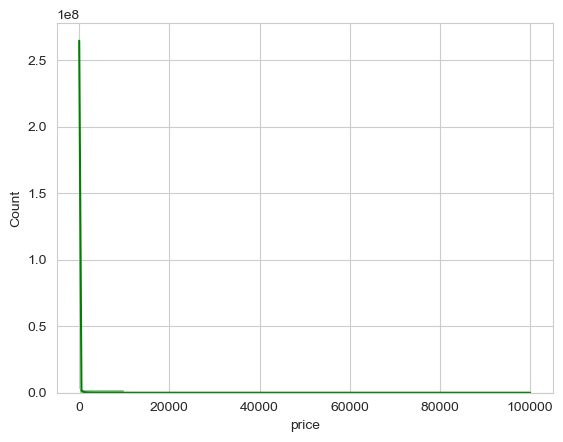

In [58]:
fig, axes = plt.subplots()
sns.histplot(df['price'], kde=True, bins=10, color="green", ax=axes);
plt.show()

In [ ]:
## Is dificult to read the grafic because have too many unique values in price to fit in this kind of grafic. 

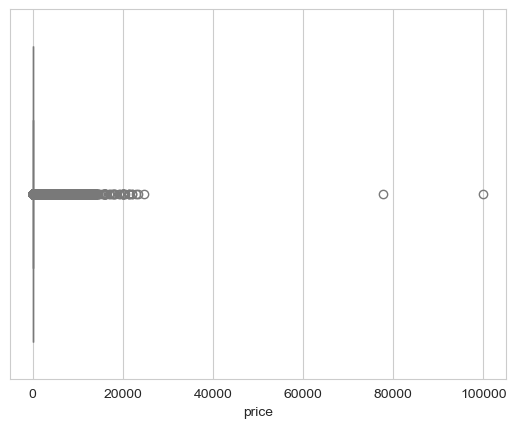

In [60]:
sns.boxplot(x = df['price'], color="lightblue");

In [ ]:
## Is posible to see at the outliers the very high value for prices. The box plot is very finn also because the outliers and because of the lower values in price for the quartiers. 

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

In [ ]:
## With this data frame is possible to use three columns to analize how customers rate the products. The most relevant are the starts. Its posible analize that the tendecy is the products have low rate.

In [63]:
df['stars'].unique()

array([4.7, 4.6, 4.5, 4.8, 0. , 4.4, 4.3, 4.1, 4.9, 5. , 3.8, 3.6, 4. ,
       4.2, 3. , 3.9, 2.5, 3.4, 3.7, 3.2, 3.3, 3.5, 2.7, 2.1, 1. , 3.1,
       2. , 2.9, 2.8, 1.5, 2.2, 2.3, 2.6, 2.4, 1.4, 1.9, 1.8, 1.7, 1.6,
       1.2, 1.3, 1.1])

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [66]:
rating = df['stars'].value_counts()

In [67]:
rating

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [70]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

print(mean_rating)
print(median_rating)
print(mode_rating)

2.152836472966065
0.0
0.0


In [ ]:
## The most commum rate is near 0. Low rates are the most commum rates for the products.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [72]:
variance_rating = df['stars'].var()
std_dev_rating = df['stars'].std()
min_rating = df['stars'].min()
max_rating = df['stars'].max()
range_rating = max_rating - min_rating
quantiles_rating = df['stars'].quantile([0.25, 0.5, 0.75])

print(variance_rating)
print(std_dev_rating)
print(min_rating)
print(max_rating)
print(range_rating)
print(quantiles_rating)

4.81743402976196
2.1948653785054697
0.0
5.0
5.0
0.25    0.0
0.50    0.0
0.75    4.4
Name: stars, dtype: float64


In [ ]:
## The data present a wide variation. With a concentrtion on lowers ratings. 

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [73]:
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(0.08120735761080985, -1.9260061280432985)

In [ ]:
## By the skewness, we can see a slightly right indication. And by the kurtosis we can note that do not have peak distribution. 

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


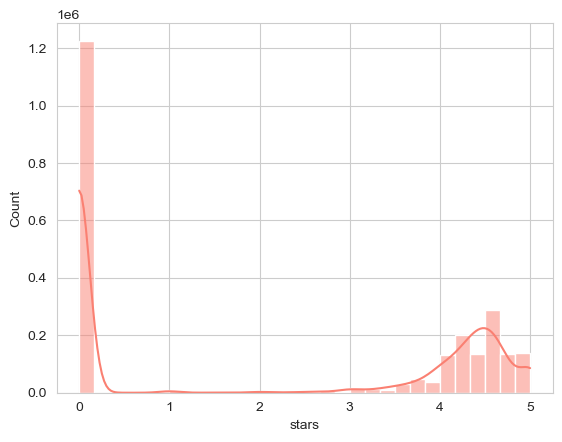

In [74]:
fig, axes = plt.subplots()
sns.histplot(df['stars'], kde=True, bins=30, color="salmon", ax=axes);
plt.show()